# DETR: End to End Object Detection with Transformers

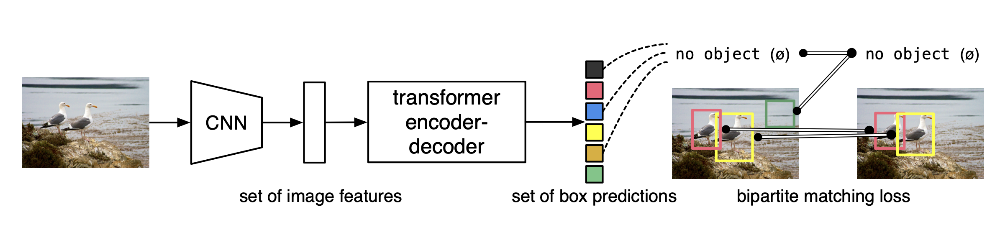

[Paper](https://arxiv.org/abs/2005.12872)


In this notebook, we will infer the DETR model on images and videos

In [1]:
# installing required libraries
!pip install -q timm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 42.4/42.4 kB 1.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.3/2.3 MB 36.1 MB/s eta 0:00:00


In [2]:
# importing required libraries
import torch
from transformers import DetrForObjectDetection, DetrImageProcessor
import cv2
import matplotlib.pyplot as plt
import numpy as np
from glob import glob
import os


## Download Inference Dataset

Download some random images for prediction. These images are taken from COCO dataset.

In [3]:
!wget "https://www.dropbox.com/scl/fi/ekllt8pwum1cu41ohsddh/inference_data.zip?rlkey=b1iih9q1mct5vcnwiyw98ouup&st=uncr8qho&dl=1" -O inference_data.zip

--2024-10-14 09:55:46--  https://www.dropbox.com/scl/fi/ekllt8pwum1cu41ohsddh/inference_data.zip?rlkey=b1iih9q1mct5vcnwiyw98ouup&st=uncr8qho&dl=1
Resolving www.dropbox.com (www.dropbox.com)... 162.125.65.18, 2620:100:6017:18::a27d:212
Connecting to www.dropbox.com (www.dropbox.com)|162.125.65.18|:443... connected.
HTTP request sent, awaiting response... 302 Found
Location: https://uc27d1e95b8205f9919c5aa5c845.dl.dropboxusercontent.com/cd/0/inline/CcYQazH15A33OB21RBMvwV4iMHc3yRRlWp2An4_OSTh6EL67BvldOii4USRW7VbOoVUEdXk44DN3Q6xqNJZndrX6McHR9XUgTvcfSRDfqx5laLoZPzCiGoG_3h95KMgFumtX-dJKg5Jy3cUNKyyLyNXR/file?dl=1# [following]
--2024-10-14 09:55:48--  https://uc27d1e95b8205f9919c5aa5c845.dl.dropboxusercontent.com/cd/0/inline/CcYQazH15A33OB21RBMvwV4iMHc3yRRlWp2An4_OSTh6EL67BvldOii4USRW7VbOoVUEdXk44DN3Q6xqNJZndrX6McHR9XUgTvcfSRDfqx5laLoZPzCiGoG_3h95KMgFumtX-dJKg5Jy3cUNKyyLyNXR/file?dl=1
Resolving uc27d1e95b8205f9919c5aa5c845.dl.dropboxusercontent.com (uc27d1e95b8205f9919c5aa5c845.dl.dropboxuserc

In [4]:
# unzip the downloaded zip file
!unzip inference_data.zip

Archive:  inference_data.zip
   creating: inference_data/
   creating: inference_data/videos/
  inflating: inference_data/videos/cycle.mp4  
  inflating: inference_data/videos/kids_walking.mp4  
  inflating: inference_data/videos/city2.mp4  
  inflating: inference_data/videos/bike.mp4  
  inflating: inference_data/videos/horse_on_beach.mp4  
   creating: inference_data/images/
  inflating: inference_data/images/000000561746.jpg  
  inflating: inference_data/images/000000387515.jpg  
  inflating: inference_data/images/000000052123.jpg  
  inflating: inference_data/images/000000129030.jpg  
  inflating: inference_data/images/000000028887.jpg  


## Load Model

In [5]:
# Initialize the model and image processor
model = DetrForObjectDetection.from_pretrained("facebook/detr-resnet-50")
processor = DetrImageProcessor.from_pretrained("facebook/detr-resnet-50")

/usr/local/lib/python3.10/dist-packages/huggingface_hub/utils/_token.py:89: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


config.json:   0%|          | 0.00/4.59k [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/167M [00:00<?, ?B/s]

model.safetensors:   0%|          | 0.00/102M [00:00<?, ?B/s]

Some weights of the model checkpoint at facebook/detr-resnet-50 were not used when initializing DetrForObjectDetection: ['model.backbone.conv_encoder.model.layer1.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer2.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer3.0.downsample.1.num_batches_tracked', 'model.backbone.conv_encoder.model.layer4.0.downsample.1.num_batches_tracked']
- This IS expected if you are initializing DetrForObjectDetection from the checkpoint of a model trained on another task or with another architecture (e.g. initializing a BertForSequenceClassification model from a BertForPreTraining model).
- This IS NOT expected if you are initializing DetrForObjectDetection from the checkpoint of a model that you expect to be exactly identical (initializing a BertForSequenceClassification model from a BertForSequenceClassification model).


preprocessor_config.json:   0%|          | 0.00/290 [00:00<?, ?B/s]

## Image Inference

In [23]:
def calculate_label_size(box_width, box_height, frame_width, frame_height, min_scale=0.4, max_scale=1.2):
    """
    Calculate appropriate font scale based on bounding box size and frame dimensions.
    """
    box_size_ratio = (box_width * box_height) / (frame_width * frame_height)
    font_scale = min_scale + (np.log(1 + box_size_ratio * 100) / 5) * (max_scale - min_scale)
    return np.clip(font_scale, min_scale, max_scale)

# Predefined colors for object classes
def generate_color_palette(num_classes):
    np.random.seed(42)  # Ensure the same colors are generated every time
    return {label: tuple(np.random.randint(0, 255, 3).tolist()) for label in range(num_classes)}

# Create a color palette for each class (COCO has 91 classes by default)
colors = generate_color_palette(num_classes=91)

# Function to get the color for a specific label
def get_label_color(label):
    return colors.get(label, (0, 255, 0))  # Default to green if no label found

In [37]:
# Function to predict and plot bounding boxes
def predict_and_plot_boxes(image_path, threshold=0.9):
    # Step 1: Load and preprocess the image
    image = cv2.imread(image_path)
    image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    inputs = processor(images=image_rgb, return_tensors="pt")

    # Step 2: Run inference
    with torch.no_grad():
        outputs = model(**inputs)

    # Step 3: Post-process the results
    # Convert the outputs (logits) into bounding boxes and labels
    target_sizes = torch.tensor([image_rgb.shape[:2]])  # Image size (height, width)
    results = processor.post_process_object_detection(outputs, target_sizes=target_sizes)[0]

    # Filter boxes based on confidence score (threshold can be adjusted)
    scores = results["scores"].numpy()
    keep = scores > threshold

    boxes = results["boxes"].numpy()[keep]
    labels = results["labels"].numpy()[keep]
    scores = scores[keep]

    for box, label, score in zip(boxes, labels, scores):
        xmin, ymin, xmax, ymax = box
        box_width = xmax - xmin
        box_height = ymax - ymin
        img_width, img_height = image_rgb.shape[:2]
        font_scale = calculate_label_size(box_width, box_height, img_width, img_height, max_scale=1)

        label_text = f"{model.config.id2label[label]}: {score:.2f}"
        (text_width, text_height), baseline = cv2.getTextSize(
            label_text,
            cv2.FONT_HERSHEY_SIMPLEX,
            font_scale,
            1
        )

        # Get the color for this label
        color = get_label_color(label)

        # Draw rectangle and label with the same color for the same class
        cv2.rectangle(image_rgb, (int(xmin), int(ymin)), (int(xmax), int(ymax)), color, max(2, int(font_scale * 3)))
        cv2.rectangle(image_rgb, (int(xmin), int(ymin) - text_height - baseline - 5),
                      (int(xmin) + text_width, int(ymin)), color, -1)
        cv2.putText(image_rgb, label_text, (int(xmin), int(ymin) - baseline - 2),
                    cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0, 0, 0), max(1, int(font_scale * 1.5)), cv2.LINE_AA)

    # Step 5: Plot the image with bounding boxes
    plt.figure(figsize=(10, 10))
    plt.imshow(image_rgb)
    plt.axis("off")  # Hide axes
    plt.show()


## Plot the images

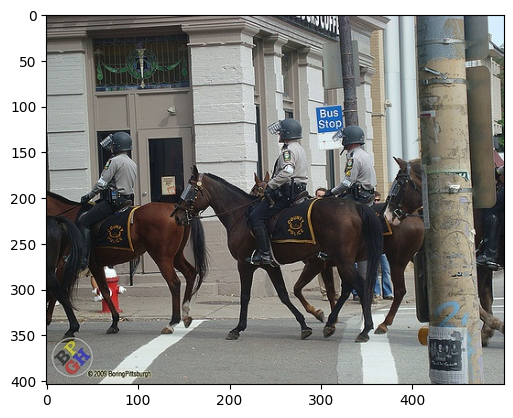

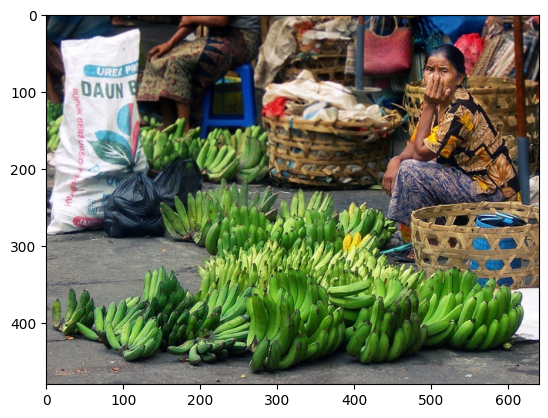

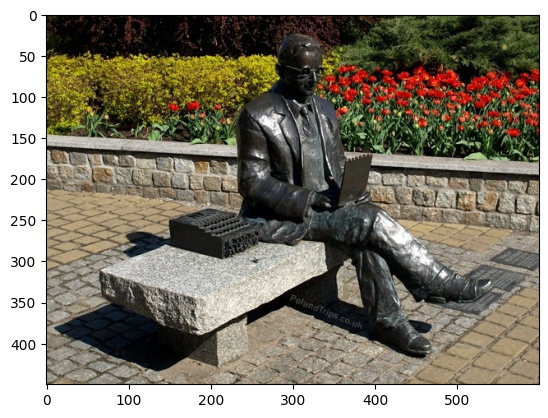

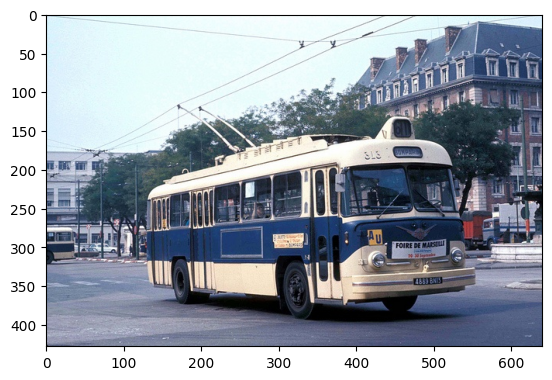

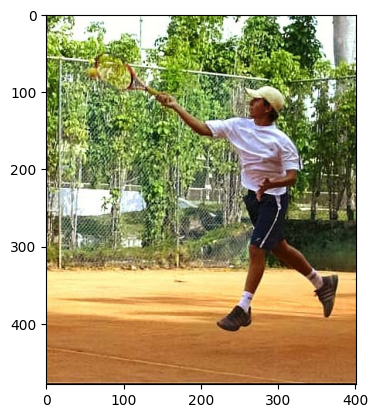

In [38]:
total_images = glob("inference_data/images/*.jpg")

for image_path in total_images:
  img = cv2.imread(image_path)
  plt.imshow(img[:,:,::-1]); plt.show();

## Predicing on the images

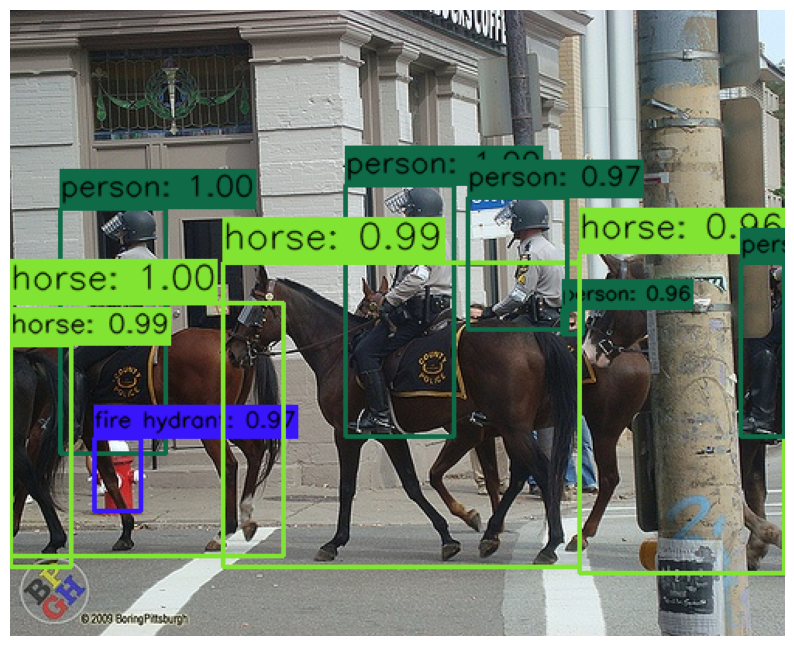

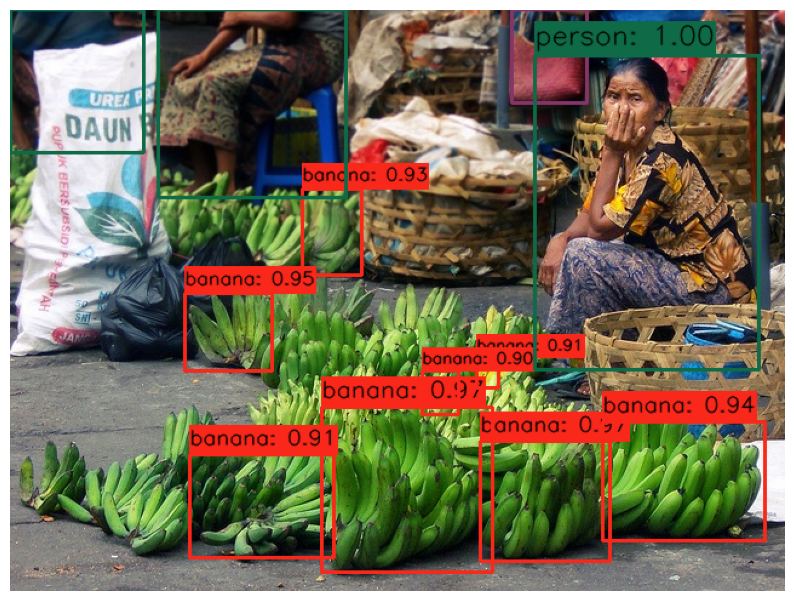

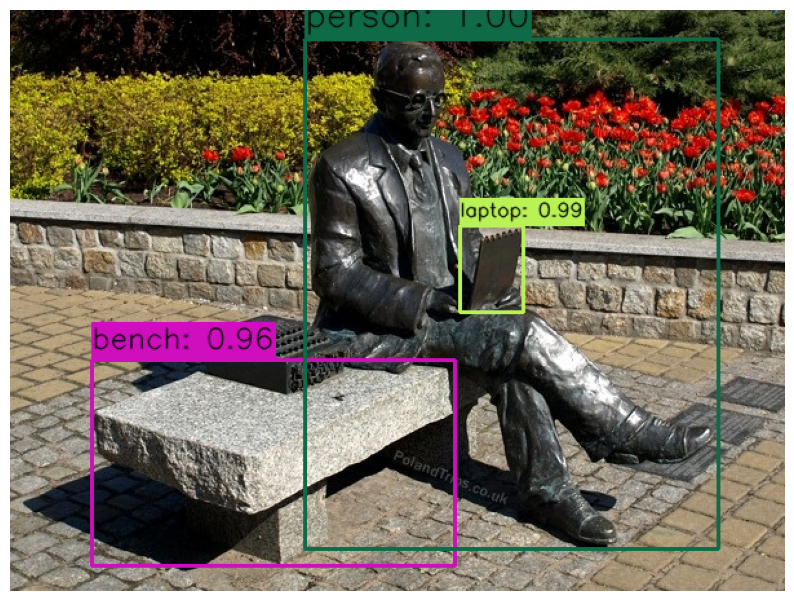

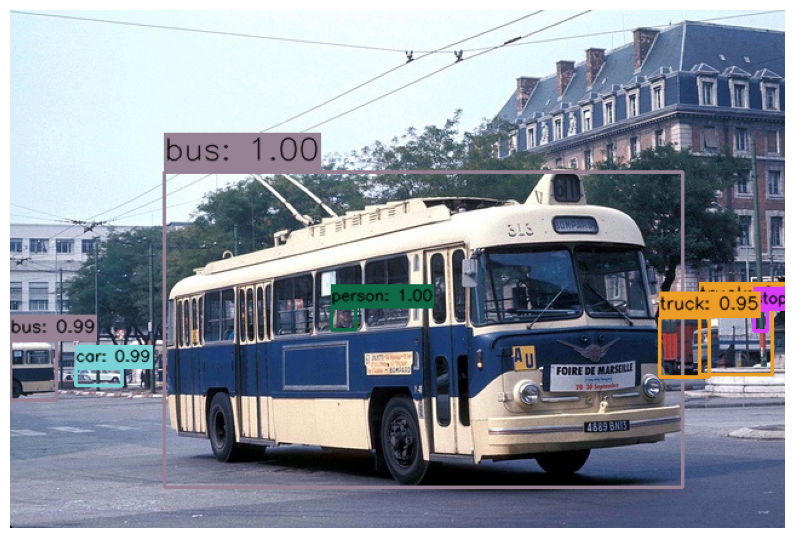

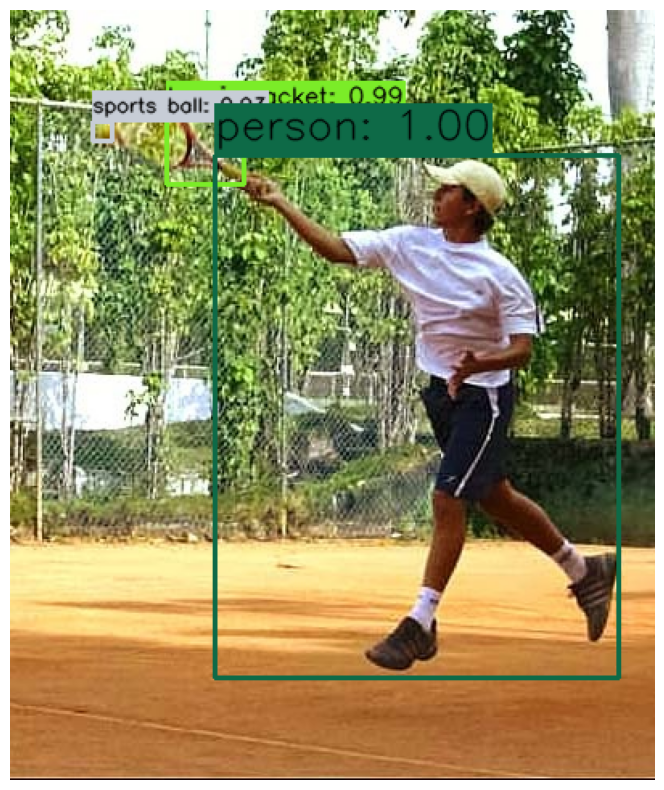

In [39]:
for image in total_images:
  predict_and_plot_boxes(image)

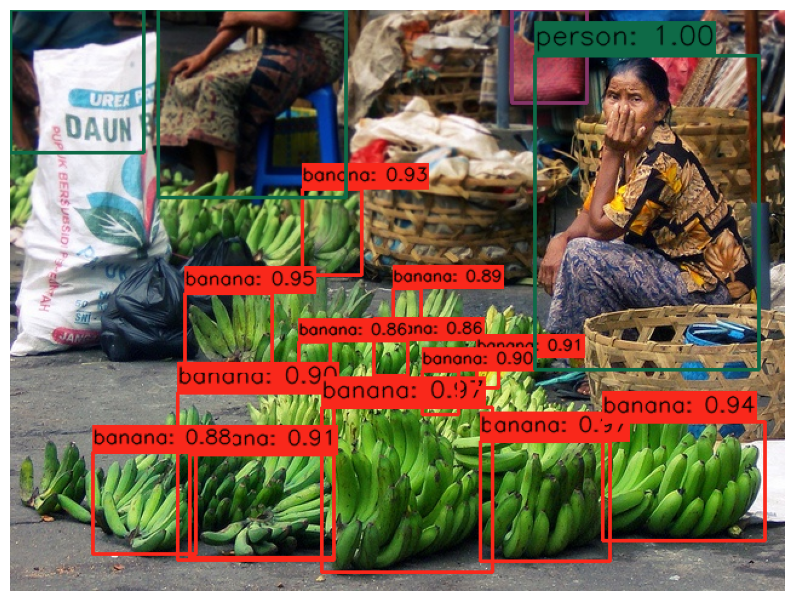

In [40]:
# predicting with lower threshold
predict_and_plot_boxes('/content/inference_data/images/000000052123.jpg', threshold=0.85)


## Video Inference

In [41]:
import torch
from tqdm import tqdm
import gc
import numpy as np
import time



def add_fps_counter(frame, fps, frame_width):
    """
    Add FPS counter to the frame.

    Args:
        frame: The video frame
        fps: Current FPS
        frame_width: Width of the frame
    """
    # Format FPS text
    fps_text = f"FPS: {fps:.1f}"

    # Set font properties
    font_scale = 0.7
    font_thickness = 2
    font = cv2.FONT_HERSHEY_SIMPLEX

    # Get text size
    (text_width, text_height), baseline = cv2.getTextSize(
        fps_text, font, font_scale, font_thickness
    )

    # Calculate position (top right corner with padding)
    padding = 10
    x = frame_width - text_width - padding
    y = text_height + padding + baseline

    # Draw background rectangle
    cv2.rectangle(
        frame,
        (int(x - 5), int(y - text_height - baseline - 5)),
        (int(x + text_width + 5), int(y + 5)),
        (0, 0, 0),
        -1
    )

    # Draw FPS text
    cv2.putText(
        frame,
        fps_text,
        (int(x), int(y)),
        font,
        font_scale,
        (255, 255, 255),  # White text
        font_thickness,
        cv2.LINE_AA
    )

def process_video(video_path, output_path):
    """
    Process a video file using GPU acceleration (if available) for object detection.
    """
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    model.to(device)

    cap = cv2.VideoCapture(video_path)
    if not cap.isOpened():
        raise ValueError("Error opening video file")

    frame_width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    frame_height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    fps = int(cap.get(cv2.CAP_PROP_FPS))
    total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

    fourcc = cv2.VideoWriter_fourcc(*'mp4v')
    out = cv2.VideoWriter(output_path, fourcc, fps, (frame_width, frame_height))

    pbar = tqdm(total=total_frames, desc="Processing frames",
                unit="frames", dynamic_ncols=True)

    frame_count = 0 # To count total frames.
    total_fps = 0 # To get the final frames per second.

    try:
        while cap.isOpened():
            ret, frame = cap.read()
            if not ret:
                break

            # Start timing for this frame
            start_time = time.time()

            frame_rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

            inputs = processor(images=frame_rgb, return_tensors="pt")
            inputs = {k: v.to(device) for k, v in inputs.items()}

            with torch.no_grad():
                outputs = model(**inputs)

            target_sizes = torch.tensor([frame_rgb.shape[:2]]).to(device)
            results = processor.post_process_object_detection(outputs, target_sizes=target_sizes)[0]

            scores = results["scores"].cpu().numpy()
            threshold = 0.9
            keep = scores > threshold

            boxes = results["boxes"].cpu().numpy()[keep]
            labels = results["labels"].cpu().numpy()[keep]
            scores = scores[keep]

            # Draw bounding boxes
            for box, label, score in zip(boxes, labels, scores):
                xmin, ymin, xmax, ymax = box
                box_width = xmax - xmin
                box_height = ymax - ymin
                font_scale = calculate_label_size(box_width, box_height, frame_width, frame_height)

                label_text = f"{model.config.id2label[label]}: {score:.2f}"
                (text_width, text_height), baseline = cv2.getTextSize(
                    label_text,
                    cv2.FONT_HERSHEY_SIMPLEX,
                    font_scale,
                    1
                )

                # Get the color for this label
                color = get_label_color(label)

                # Draw rectangle and label with the same color for the same class
                cv2.rectangle(frame, (int(xmin), int(ymin)), (int(xmax), int(ymax)), color, max(2, int(font_scale * 3)))
                cv2.rectangle(frame, (int(xmin), int(ymin) - text_height - baseline - 5),
                              (int(xmin) + text_width, int(ymin)), color, -1)
                cv2.putText(frame, label_text, (int(xmin), int(ymin) - baseline - 2),
                            cv2.FONT_HERSHEY_SIMPLEX, font_scale, (0, 0, 0), max(1, int(font_scale * 1.5)), cv2.LINE_AA)

            end_time = time.time()
            # Get the current fps.
            fps = 1 / (end_time - start_time)
            # Add `fps` to `total_fps`.
            total_fps += fps
            # Increment frame count.
            frame_count += 1

            # Add FPS counter to frame
            add_fps_counter(frame, fps, frame_width)

            out.write(frame)
            pbar.update(1)

            if pbar.n % 100 == 0:
                torch.cuda.empty_cache()
                gc.collect()

    except Exception as e:
        print(f"An error occurred: {e}")
        raise
    finally:
        pbar.close()
        cap.release()
        out.release()
        cv2.destroyAllWindows()
        torch.cuda.empty_cache()
        gc.collect()
        model.to('cpu')

    print("\nVideo processing completed!")

## Display one of the video

In [42]:
import moviepy.editor
moviepy.editor.ipython_display("inference_data/videos/bike.mp4")

### Run prediction on the above video

In [43]:
if not os.path.isdir("video_output"):
  os.mkdir("video_output")
process_video("inference_data/videos/bike.mp4", "video_output/bike_output.mp4")

Using device: cuda


Processing frames: 100%|██████████| 360/360 [01:18<00:00,  4.58frames/s]



Video processing completed!


Show the video output -

In [44]:
import moviepy.editor
moviepy.editor.ipython_display("video_output/bike_output.mp4")

Run prediction over all videos

In [45]:
for video in glob("inference_data/videos/*"):
  saved_video_path = os.path.join('video_output',video.split("/")[-1])
  process_video(video, saved_video_path)

Using device: cuda


Processing frames: 100%|██████████| 236/236 [00:45<00:00,  5.23frames/s]



Video processing completed!
Using device: cuda


Processing frames: 100%|██████████| 330/330 [00:59<00:00,  5.54frames/s]



Video processing completed!
Using device: cuda


Processing frames: 100%|██████████| 547/547 [01:19<00:00,  6.92frames/s]



Video processing completed!
Using device: cuda


Processing frames: 100%|██████████| 414/414 [01:04<00:00,  6.39frames/s]



Video processing completed!
Using device: cuda


Processing frames: 100%|██████████| 360/360 [01:06<00:00,  5.39frames/s]



Video processing completed!


In [46]:
!zip -r output_videos.zip video_output

  adding: video_output/ (stored 0%)
  adding: video_output/cycle.mp4 (deflated 2%)
  adding: video_output/horse_on_beach.mp4 (deflated 2%)
  adding: video_output/kids_walking.mp4 (deflated 1%)
  adding: video_output/bike_output.mp4 (deflated 1%)
  adding: video_output/city2.mp4 (deflated 0%)
  adding: video_output/bike.mp4 (deflated 1%)
